# Week 5 — Word Embeddings: From Word IDs to Learning from Context
**CSS371: Natural Language Processing
| Topics | Core activity |
|---|---|
| 1. | IDs and one-hot limitations |
| 2. | Embedding lookup and shapes |
| 3. | Geometry and similarity |
| 4. | Context windows and counts |
| 5. | Skip-gram arithmetic, pseudocode, and gradients |
| 6. | Run Skip-gram and inspect neighbors |
| 7. | CBOW: explanation, calculation, pseudocode, and code |
| 8. | GloVe: explanation, calculation, pseudocode, and code |
| 9. | Compare the three methods |
| 10. | Use embeddings and discuss limitations |
| 11. | One guided exercise and discussion |


## Setup — run once
The core uses Python, NumPy, Matplotlib, and PyTorch. It runs on a CPU and needs no dataset downloads,
API keys, pretrained weights, or GPU. If a package is missing, uncomment the installation line below,
run it, and restart the kernel if requested. Installation needs internet access; the lesson itself does not.


In [33]:
# Uncomment only if these packages are not installed in your notebook environment.
# %pip install numpy matplotlib torch

import sys
import random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # Small classroom matrices do not need many CPU threads.
DEVICE = torch.device('cpu')
print(f'Python {sys.version.split()[0]} | PyTorch {torch.__version__} | device={DEVICE}')


Python 3.13.15 | PyTorch 2.11.0+cpu | device=cpu


## 1. Why do words need representations?
A neural network operates on numbers. A vocabulary assigns each token a unique integer, but that integer
is an **address**, not a measurement. If `cat=0`, `dog=1`, and `car=2`, it does not follow that a dog
is halfway between a cat and a car. Reordering the dictionary should not change word meaning.

A **one-hot vector** assigns one coordinate to each vocabulary item. For vocabulary size $V$,
the vector $x_w\in\mathbb{R}^{V}$ has a 1 at word $w$'s index and zeros elsewhere.
For two different words, $x_a^\top x_b=0$ and $\|x_a-x_b\|_2=\sqrt{2}$.
All distinct words are equally far apart: this encoding identifies words but does not express graded semantic similarity.

**Predict:** Will one-hot cosine similarity say *cat* is closer to *dog* than to *car*?


In [34]:
demo_words = ['cat', 'dog', 'car', 'bus', 'milk', 'road']
demo_ids = {word: i for i, word in enumerate(demo_words)}
one_hot = torch.eye(len(demo_words))  # Shape: [V, V]; each row is one word.
print('One-hot vector for cat:', one_hot[demo_ids['cat']].tolist())
for other in ['dog', 'car']:
    a, b = one_hot[demo_ids['cat']], one_hot[demo_ids[other]]
    print(f'cat vs {other}: dot={a @ b:.1f}, distance={torch.linalg.vector_norm(a-b):.3f}')


One-hot vector for cat: [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
cat vs dog: dot=0.0, distance=1.414
cat vs car: dot=0.0, distance=1.414


**Interpretation:** Both distances are approximately 1.414. One-hot encoding is useful for identification,
but semantic relationships must be learned elsewhere in the model.
With $V=50{,}000$, a literal dense one-hot vector contains 49,999 zeros. In practice, we pass integer IDs
and use lookup operations instead of allocating these vectors.

**Check:** Why would subtracting two token IDs be misleading?
<details><summary>Suggested answer</summary>
Vocabulary ordering is arbitrary. Renumbering the same words changes numerical differences without changing meaning.
</details>


## 2. Embeddings are trainable tables
An embedding represents each word by $D$ real-valued coordinates, usually with $D\ll V$.
Collect these vectors in an **embedding table** $E\in\mathbb{R}^{V\times D}$.
If $x_w$ is a one-hot **column** vector, then

$$e_w=E^\top x_w\in\mathbb{R}^{D}.$$

This multiplication selects the row indexed by $w$ (written as a column vector mathematically).
Code uses the cheaper equivalent operation `E[word_id]`.

**Worked example:** If the first row of $E$ is $[1,0,0.5]$ and $x_{cat}=[1,0,0,0,0,0]^\top$,
then $E^\top x_{cat}=[1,0,0.5]^\top$: the other rows are multiplied by zero.

**Predict:** For a batch of 2 sequences with 4 IDs each and $D=3$, what is the output shape?


In [35]:
# These numbers are handcrafted for lookup arithmetic, not learned semantic vectors.
E_demo = torch.tensor([[1., 0., .5], [.8, .2, .4], [0., 1., .1],
                       [.1, .9, .2], [.5, .3, .7], [.2, .8, 0.]])
cat_id = demo_ids['cat']
by_multiplication = E_demo.T @ one_hot[cat_id]
by_lookup = E_demo[cat_id]
print('Matrix multiplication:', by_multiplication)
print('Row lookup:', by_lookup)
assert torch.allclose(by_multiplication, by_lookup)

lookup = nn.Embedding.from_pretrained(E_demo.clone(), freeze=False)
batch_ids = torch.tensor([[0, 1, 0, 2], [3, 4, 5, 1]], dtype=torch.long)
batch_vectors = lookup(batch_ids)
print('Input:', tuple(batch_ids.shape), 'Output:', tuple(batch_vectors.shape))
assert batch_vectors.shape == (2, 4, 3)
assert torch.equal(batch_vectors[0, 0], batch_vectors[0, 2])


Matrix multiplication: tensor([1.0000, 0.0000, 0.5000])
Row lookup: tensor([1.0000, 0.0000, 0.5000])
Input: (2, 4) Output: (2, 4, 3)


### What is learned?
An ordinary `nn.Embedding(V, D)` begins with random values. Training changes its entries to help an objective.
The lookup operation itself does not teach the model language.

| Quantity | Shape | Meaning |
|---|---|---|
| Embedding table | $[V,D]$ | One trainable row per vocabulary item |
| Input IDs | $[B,T]$ | Batch size $B$, sequence length $T$ |
| Output vectors | $[B,T,D]$ | One vector per input position |

The table has $VD$ parameters. With $V=50{,}000$ and $D=100$, that is 5 million values,
or about 20 MB using 32-bit floats, excluding gradients and optimizer state.
Dense embeddings reduce each word representation's dimension, but the complete table still consumes memory.

**Misconception:** Dimension 1 is not necessarily “animalness.” Information is usually distributed over coordinates.
For any orthogonal matrix $Q$, transforming all vectors by $Q$ preserves dot products:
$(Qa)^\top(Qb)=a^\top b$. Geometry can remain the same even when coordinate values change.


## 3. Geometry: what does “similar” mean?
For nonzero vectors $a,b\in\mathbb{R}^{D}$:

$$a^\top b=\sum_{i=1}^{D}a_i b_i,\qquad
\|a\|_2=\sqrt{\sum_i a_i^2},\qquad
d(a,b)=\sqrt{\sum_i(a_i-b_i)^2}.$$

The dot product depends on direction **and** magnitude. Euclidean distance measures straight-line separation.
Cosine similarity compares directions:

$$\operatorname{cos}(a,b)=\frac{a^\top b}{\|a\|_2\|b\|_2}\in[-1,1].$$

**Worked example:** For $a=[1,0]$ and $b=[0.8,0.6]$, the dot product is 0.8,
both norms are 1, cosine is 0.8, and distance is $\sqrt{0.04+0.36}\approx0.632$.
For $c=[2,0]$, cosine with $a$ is 1 even though their distance is 1.

**Predict:** Which vector below has the largest dot product with $a$? Which has the largest cosine?


a         : dot= 1.00, cosine= 1.00, distance=0.000
b         : dot= 0.80, cosine= 0.80, distance=0.632
scaled a  : dot= 2.00, cosine= 1.00, distance=1.000
reverse a : dot=-1.00, cosine=-1.00, distance=2.000


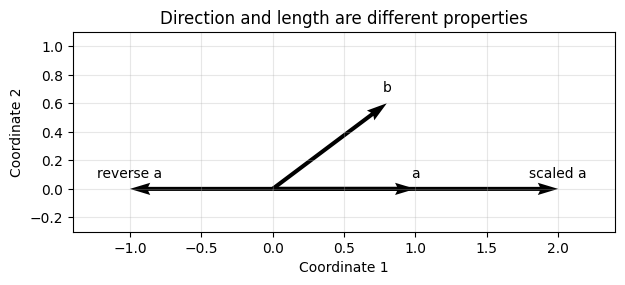

In [36]:
# Illustrative coordinates only: do not interpret these as results from training.
geometry = torch.tensor([[1., 0.], [.8, .6], [2., 0.], [-1., 0.]])
geometry_names = ['a', 'b', 'scaled a', 'reverse a']
a = geometry[0]
for label, v in zip(geometry_names, geometry):
    cosine = F.cosine_similarity(a, v, dim=0)
    distance = torch.linalg.vector_norm(a-v)
    print(f'{label:10s}: dot={a @ v:5.2f}, cosine={cosine:5.2f}, distance={distance:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, v in zip(geometry_names, geometry.numpy()):
    ax.quiver(0, 0, *v, angles='xy', scale_units='xy', scale=1)
    ax.text(v[0], v[1] + .08, label, ha='center')
ax.set(xlim=(-1.4, 2.4), ylim=(-.3, 1.1), xlabel='Coordinate 1', ylabel='Coordinate 2',
       title='Direction and length are different properties')
ax.set_aspect('equal')
ax.grid(alpha=.3)
plt.show()


**Interpretation:** Positive rescaling leaves cosine unchanged. A negative cosine means opposing vector directions;
it does **not** establish linguistic antonymy. Zero vectors have undefined mathematical cosine because the
denominator is zero; libraries use numerical safeguards, which do not give zero vectors a meaningful direction.

**Similarity versus association:** *cat/dog* can fill similar grammatical and semantic roles;
*cat/milk* are associated but not interchangeable. *Hot/cold* are antonyms yet often occur in similar contexts.
An embedding's neighbors depend on the corpus and objective, not a universal definition of meaning.


## 4. Learn from surrounding words
The **distributional hypothesis** motivates learning from context: words that occur in similar contexts
often have related meanings. Compare “the cat eats food” and “the dog eats food.”
The shared contexts provide a signal even if *cat* and *dog* never occur next to each other.

We will use a deliberately balanced, **synthetic** corpus. Repeated sentence patterns make the mechanism
visible; they are not evidence that the model learns real-world language well.
Our tokenizer simply splits lowercase text on whitespace. Real tokenization must address punctuation,
languages, morphology, and the difference between words and subword tokens.


In [37]:
# Everything needed for training is defined here: no external text files.
sentences = []
for animal in ['cat', 'dog', 'rabbit']:
    sentences.extend([f'the {animal} eats food', f'the {animal} drinks water',
                      f'the {animal} sleeps quietly', f'a small {animal} plays'])
for vehicle in ['car', 'bus', 'truck']:
    sentences.extend([f'the {vehicle} travels on road', f'the {vehicle} carries people',
                      f'the {vehicle} moves quickly', f'a large {vehicle} stops'])
tokenized = [sentence.lower().split() for sentence in sentences]
vocab = sorted({word for sentence in tokenized for word in sentence})
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = dict(enumerate(vocab))
V = len(vocab)
print(f'{len(sentences)} sentences | {sum(map(len, tokenized))} tokens | V={V}')
print('Examples:', sentences[0], '|', sentences[4])
print('Vocabulary:', vocab)


24 sentences | 99 tokens | V=25
Examples: the cat eats food | the dog eats food
Vocabulary: ['a', 'bus', 'car', 'carries', 'cat', 'dog', 'drinks', 'eats', 'food', 'large', 'moves', 'on', 'people', 'plays', 'quickly', 'quietly', 'rabbit', 'road', 'sleeps', 'small', 'stops', 'the', 'travels', 'truck', 'water']


### Dataset

In [38]:
for s in sentences:
    print(s)

the cat eats food
the cat drinks water
the cat sleeps quietly
a small cat plays
the dog eats food
the dog drinks water
the dog sleeps quietly
a small dog plays
the rabbit eats food
the rabbit drinks water
the rabbit sleeps quietly
a small rabbit plays
the car travels on road
the car carries people
the car moves quickly
a large car stops
the bus travels on road
the bus carries people
the bus moves quickly
a large bus stops
the truck travels on road
the truck carries people
the truck moves quickly
a large truck stops


### Turn text into supervised examples
A symmetric context window of radius $r$ collects up to $r$ tokens on each side of a center word,
excluding the center itself and respecting sentence boundaries.

For “the cat eats food” with $r=1$:

| Center position | Training pairs (center, context) |
|---|---|
| the | (the, cat) |
| cat | (cat, the), (cat, eats) |
| eats | (eats, cat), (eats, food) |
| food | (food, eats) |

These are **Skip-gram** examples: predict each surrounding word from a center word.
The related **CBOW** approach predicts the center from an aggregation of surrounding vectors.

**Predict:** How many pairs does this four-word sentence produce with radius 2?


In [39]:
def make_pairs(token_lists, mapping, radius=2):
    """Return (center_id, context_id), without crossing sentence boundaries."""
    pairs = []
    for words in token_lists:
        for i, center in enumerate(words):
            left, right = max(0, i-radius), min(len(words), i+radius+1)
            for j in range(left, right):
                if j != i:  # Do not use a token as its own context position.
                    pairs.append((mapping[center], mapping[words[j]]))
    return pairs

example_pairs = make_pairs([tokenized[0]], word_to_id, radius=2)
print('Radius 2:', [(id_to_word[c], id_to_word[o]) for c, o in example_pairs])
assert len(example_pairs) == 10
WINDOW_RADIUS = 2
pairs = make_pairs(tokenized, word_to_id, WINDOW_RADIUS)
pair_tensor = torch.tensor(pairs, dtype=torch.long, device=DEVICE)
center_ids, context_ids = pair_tensor[:, 0], pair_tensor[:, 1]
print('Training pairs:', len(pairs), '| ID tensor shape:', tuple(pair_tensor.shape))


Radius 2: [('the', 'cat'), ('the', 'eats'), ('cat', 'the'), ('cat', 'eats'), ('cat', 'food'), ('eats', 'the'), ('eats', 'cat'), ('eats', 'food'), ('food', 'cat'), ('food', 'eats')]
Training pairs: 252 | ID tensor shape: (252, 2)


### A count-based representation makes context visible
Let $C_{w,c}$ count how often context word $c$ appears near center word $w$.
Then $C\in\mathbb{R}^{V\times V}$ represents each center by its context-count row.
This is already a distributional representation, but it becomes large and sparse for realistic vocabularies.
Frequent words may dominate raw counts. Neural embeddings learn a lower-dimensional representation through an objective;
we will not directly factorize $C$ in the core lesson.

**Predict:** Will the rows for *cat* and *dog* match in this constructed corpus?


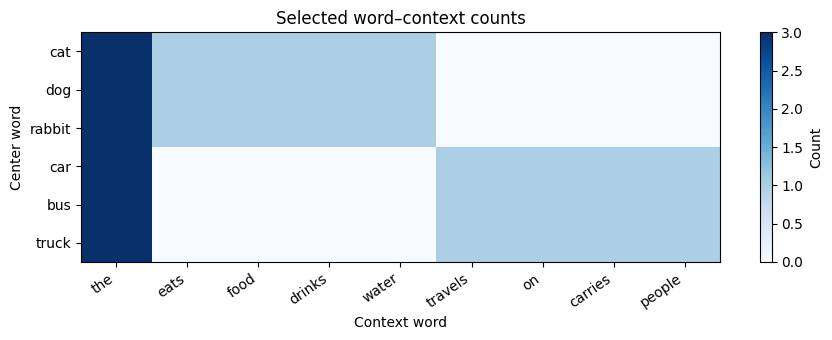

cat/dog count-row cosine: 1.0


In [40]:
C = torch.zeros(V, V)
for center, context in pairs:
    C[center, context] += 1
selected_words = ['cat', 'dog', 'rabbit', 'car', 'bus', 'truck']
selected_contexts = ['the', 'eats', 'food', 'drinks', 'water', 'travels', 'on', 'carries', 'people']
rows = [word_to_id[w] for w in selected_words]
cols = [word_to_id[w] for w in selected_contexts]
fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(C[rows][:, cols].numpy(), cmap='Blues', aspect='auto')
ax.set_xticks(range(len(cols)), selected_contexts, rotation=35, ha='right')
ax.set_yticks(range(len(rows)), selected_words)
ax.set(xlabel='Context word', ylabel='Center word', title='Selected word–context counts')
fig.colorbar(im, ax=ax, label='Count')
plt.tight_layout()
plt.show()
print('cat/dog count-row cosine:', round(F.cosine_similarity(C[rows[0]], C[rows[1]], dim=0).item(), 4))


In [41]:
C.numpy()

array([[0., 1., 1., 0., 1., 1., 0., 0., 0., 3., 0., 0., 0., 0., 0., 0.,
        1., 0., 0., 3., 0., 0., 0., 1., 0.],
       [1., 0., 0., 1., 0., 0., 0., 0., 0., 1., 1., 1., 1., 0., 1., 0.,
        0., 0., 0., 0., 1., 3., 1., 0., 0.],
       [1., 0., 0., 1., 0., 0., 0., 0., 0., 1., 1., 1., 1., 0., 1., 0.,
        0., 0., 0., 0., 1., 3., 1., 0., 0.],
       [0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 3., 0., 0., 0.,
        0., 0., 0., 0., 0., 3., 0., 1., 0.],
       [1., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 1., 0., 1.,
        0., 0., 1., 1., 0., 3., 0., 0., 1.],
       [1., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 1., 0., 1.,
        0., 0., 1., 1., 0., 3., 0., 0., 1.],
       [0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0., 0., 0., 3., 0., 0., 3.],
       [0., 0., 0., 0., 1., 1., 0., 0., 3., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0., 0., 0., 3., 0., 0., 0.],
       [0., 0., 0., 0., 1., 1., 0., 3., 0., 0., 0., 0., 0., 0., 

## 5. Skip-gram: from one pair to a loss
We need a differentiable objective that rewards predicting observed context words.
Skip-gram uses **two** trainable tables:

| Symbol | Shape | Role |
|---|---|---|
| $E$ | $V\times D$ | Center/input embeddings; row $w$ is $v_w^\top$ |
| $U$ | $V\times D$ | Context/output embeddings; row $o$ is $u_o^\top$ |
| $s$ | $V$ | Scores for every candidate context word |

For observed pair $(w,o)$:

$$s_j=u_j^\top v_w,\qquad
P(j\mid w)=\frac{\exp(s_j)}{\sum_{k=1}^{V}\exp(s_k)},\qquad
\mathcal{L}(w,o)=-\log P(o\mid w).$$

1. **Lookup:** retrieve the center vector $v_w$.
2. **Score:** dot it with every row of $U$; higher scores mean greater compatibility under the model.
3. **Normalize:** softmax produces nonnegative probabilities summing to one.
4. **Measure error:** negative log-likelihood penalizes low probability for the observed context.

For $N$ pairs, minimize their average loss: $\mathcal{J}=\frac1N\sum_{n=1}^{N}\mathcal{L}(w_n,o_n)$.
We predict one context position at a time; multiple valid contexts for one center contribute multiple pairs.

### Worked numerical example
Let $v_w=[1,0]^\top$, and let three candidate context vectors be
$u_0=[1,0]^\top$, $u_1=[0,1]^\top$, and $u_2=[-1,0]^\top$.
Then scores are $[1,0,-1]$ and probabilities are approximately $[0.665,0.245,0.090]$.
If the observed context is candidate 1, the loss is $-\log(0.245)\approx1.408$.

**Predict:** Would the loss be smaller if candidate 0 were the observed context?


In [42]:
v_small = torch.tensor([1., 0.])
U_small = torch.tensor([[1., 0.], [0., 1.], [-1., 0.]])
scores_small = U_small @ v_small
probabilities_small = torch.softmax(scores_small, dim=0)
target_small = torch.tensor([1])
manual_loss = -torch.log(probabilities_small[1])
library_loss = F.cross_entropy(scores_small.unsqueeze(0), target_small)
print('Scores:', scores_small.tolist())
print('Probabilities:', probabilities_small.tolist())
print(f'Manual loss: {manual_loss:.4f} | cross_entropy: {library_loss:.4f}')
assert torch.allclose(probabilities_small.sum(), torch.tensor(1.))
assert torch.allclose(manual_loss, library_loss)
# cross_entropy takes RAW SCORES (logits), not already-softmaxed probabilities.
# It combines log-softmax and negative log-likelihood using stable arithmetic.


Scores: [1.0, 0.0, -1.0]
Probabilities: [0.6652409434318542, 0.2447284758090973, 0.09003057330846786]
Manual loss: 1.4076 | cross_entropy: 1.4076


### Why do the vectors change?
For score $s_j$, the derivative is

$$\frac{\partial\mathcal{L}}{\partial s_j}=P(j\mid w)-\mathbf{1}[j=o].$$

For the observed class, this is $P(o\mid w)-1<0$: gradient descent encourages a higher score.
For another class, it is $P(j\mid w)>0$: gradient descent encourages a lower score.
Shared parameters and multiple examples mean not every individual score must move this way in a batch update.
Backpropagation carries these signals into both embedding tables.

For parameters $\theta$, an SGD update is $\theta\leftarrow\theta-\eta\nabla_\theta\mathcal{J}$,
where $\eta$ is the learning rate. Our training code uses Adam, which adapts update sizes using gradient history.

**Why two tables?** A word plays two roles: the input we condition on and the output we predict.
Separate tables let the model parameterize these roles independently. They have the same vocabulary but different values.
We will use **$E$, the center table**, when retrieving neighbors. Some applications use the context table or combine them;
that is an additional design choice.


In [43]:
# Observe one backward pass: only the selected input row participates in this lookup.
torch.manual_seed(SEED)
input_demo = nn.Embedding(3, 2)
output_demo = nn.Embedding(3, 2)
with torch.no_grad():
    input_demo.weight[0].copy_(v_small)
    output_demo.weight.copy_(U_small)
single_logits = input_demo(torch.tensor([0])) @ output_demo.weight.T
single_loss = F.cross_entropy(single_logits, target_small)
single_loss.backward()
print('Input-table gradients:', input_demo.weight.grad)
print('Output-table gradients:', output_demo.weight.grad)
assert torch.count_nonzero(input_demo.weight.grad[1:]) == 0
# Full softmax uses every output row, so even unobserved output classes receive gradients.


Input-table gradients: tensor([[ 0.5752, -0.7553],
        [ 0.0000,  0.0000],
        [ 0.0000,  0.0000]])
Output-table gradients: tensor([[ 0.6652,  0.0000],
        [-0.7553, -0.0000],
        [ 0.0900,  0.0000]])


## 6. Train a complete small model
For $B$ training pairs, the computation is:

$$[B]\;\text{IDs}\rightarrow[B,D]\;\text{center vectors}
\rightarrow[B,D][D,V]=[B,V]\;\text{logits}\rightarrow\text{scalar mean loss}.$$

The model below has $2VD$ parameters and no output bias. Full softmax is practical for our small vocabulary;
it scores all $V$ output words for each example. We use the entire pair dataset in each update to keep the code transparent.
An epoch here is one update using all pairs; larger datasets normally require many minibatch updates per epoch.


### Skip-gram pseudocode — before coding the model
```text
extract (center, context) pairs within each sentence window
initialize center table E and context table U
repeat for each epoch:
    v = E[all center IDs]
    logits = v @ transpose(U)
    loss = mean cross_entropy(logits, observed context IDs)
    clear gradients; backpropagate; update both tables
return E and U as the word vectors used for neighbor inspection
```
Trace one pair using the worked calculation above before running the full implementation.



1. V BEFORE TRAINING
   Center / Input Embedding Matrix
tensor([[-0.1034, -0.0218,  0.0799,  0.0910, -0.0088],
        [ 0.0337,  0.0973, -0.1015,  0.0387,  0.0734],
        [ 0.0251,  0.0077, -0.0206,  0.2170,  0.2021],
        [ 0.0254, -0.0278, -0.0612, -0.0557, -0.0968],
        [ 0.0871, -0.0096,  0.0404, -0.0714,  0.0857],
        [-0.0672,  0.1068, -0.0253, -0.0188, -0.0771],
        [ 0.0180, -0.2127,  0.1859,  0.0056,  0.0769],
        [ 0.2557,  0.0572,  0.1360,  0.0433, -0.0717],
        [-0.1973, -0.1412,  0.1736,  0.1835,  0.0880],
        [ 0.0056,  0.0378,  0.0705, -0.0222, -0.1247],
        [-0.0486, -0.0336,  0.0037,  0.0493,  0.0885],
        [ 0.0182,  0.1893,  0.0445,  0.0136,  0.0309],
        [ 0.1662,  0.0175,  0.0608,  0.1631,  0.2852],
        [-0.0744,  0.0195, -0.1335,  0.0395,  0.1706],
        [-0.0794,  0.0375,  0.0076, -0.0213, -0.0566],
        [ 0.0399,  0.1369, -0.0252,  0.1900,  0.1695],
        [ 0.0306,  0.0291,  0.0409, -0.1261,  0.0917],
        

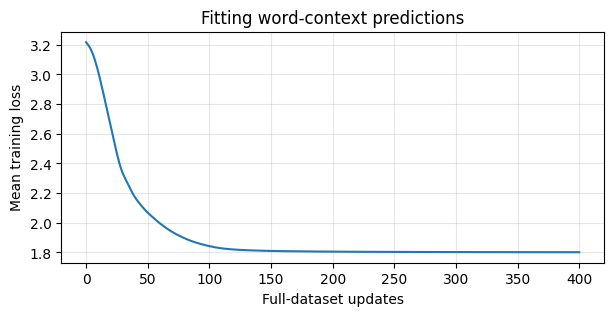

In [52]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Skip-Gram Model
# ============================================================

class SkipGram(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()

        # V: Center / Input embedding matrix
        self.center = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # U: Context / Output embedding matrix
        self.context = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Random initialization
        nn.init.normal_(
            self.center.weight,
            mean=0.,
            std=.1
        )

        nn.init.normal_(
            self.context.weight,
            mean=0.,
            std=.1
        )

    def forward(self, ids):

        # ----------------------------------------------------
        # Step 1: Lookup center vectors from V
        #
        # ids:
        #     [B]
        #
        # center_vectors:
        #     [B, D]
        # ----------------------------------------------------

        center_vectors = self.center(ids)

        # ----------------------------------------------------
        # Step 2: Calculate scores against ALL context words
        #
        # center_vectors          : [B, D]
        # self.context.weight     : [V, D]
        # self.context.weight.T   : [D, V]
        #
        # logits:
        #     [B, V]
        #
        # Each row contains scores for all vocabulary words.
        # ----------------------------------------------------

        logits = center_vectors @ self.context.weight.T

        return logits


# ============================================================
# Training Function
# ============================================================

def train_skipgram(
    center_ids,
    context_ids,
    vocab_size,
    dim=3,
    epochs=400,
    lr=.03,
    seed=42
):

    # Make random initialization reproducible
    torch.manual_seed(seed)

    # --------------------------------------------------------
    # Create model
    # --------------------------------------------------------

    model = SkipGram(
        vocab_size,
        dim
    ).to(DEVICE)


    # ========================================================
    # Save embeddings BEFORE training
    # ========================================================

    # V before training
    initial_V = (
        model.center.weight
        .detach()
        .clone()
    )

    # U before training
    initial_U = (
        model.context.weight
        .detach()
        .clone()
    )


    # --------------------------------------------------------
    # Optimizer
    #
    # model.parameters() contains BOTH:
    #
    #   model.center.weight   -> V
    #   model.context.weight  -> U
    #
    # Therefore Adam will update both V and U.
    # --------------------------------------------------------

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )


    # ========================================================
    # Initial loss BEFORE training
    # ========================================================

    with torch.no_grad():

        initial_logits = model(center_ids)

        initial_loss = F.cross_entropy(
            initial_logits,
            context_ids
        ).item()

        history = [initial_loss]


    # ========================================================
    # Training Loop
    # ========================================================

    for epoch in range(epochs):

        # ----------------------------------------------------
        # Forward Pass
        # ----------------------------------------------------

        logits = model(center_ids)


        # ----------------------------------------------------
        # Cross Entropy Loss
        #
        # logits      : [B, V]
        # context_ids : [B]
        #
        # F.cross_entropy internally performs:
        #
        #     Softmax + Negative Log Likelihood
        #
        # ----------------------------------------------------

        loss = F.cross_entropy(
            logits,
            context_ids
        )


        # ----------------------------------------------------
        # Clear old gradients
        # ----------------------------------------------------

        optimizer.zero_grad()


        # ----------------------------------------------------
        # Backpropagation
        #
        # Compute:
        #
        #     dL/dV
        #     dL/dU
        #
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # Update BOTH V and U
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # Save loss after each update
        # ----------------------------------------------------

        with torch.no_grad():

            current_loss = F.cross_entropy(
                model(center_ids),
                context_ids
            ).item()

            history.append(current_loss)


    # ========================================================
    # Return Model + V_before + U_before + Loss History
    # ========================================================

    return model, initial_V, initial_U, history


# ============================================================
# Train Skip-Gram
# ============================================================

DIM = 5

model, initial_V, initial_U, loss_history = train_skipgram(
    center_ids,
    context_ids,
    V,
    dim=DIM
)


# ============================================================
# Save embeddings AFTER training
# ============================================================

# V after training
learned_V = (
    model.center.weight
    .detach()
    .clone()
)

# U after training
learned_U = (
    model.context.weight
    .detach()
    .clone()
)


# ============================================================
# Display FOUR Embedding Matrices
# ============================================================

print("\n" + "=" * 70)
print("1. V BEFORE TRAINING")
print("   Center / Input Embedding Matrix")
print("=" * 70)

print(initial_V)


print("\n" + "=" * 70)
print("2. U BEFORE TRAINING")
print("   Context / Output Embedding Matrix")
print("=" * 70)

print(initial_U)


print("\n" + "=" * 70)
print("3. V AFTER TRAINING")
print("   Center / Input Embedding Matrix")
print("=" * 70)

print(learned_V)


print("\n" + "=" * 70)
print("4. U AFTER TRAINING")
print("   Context / Output Embedding Matrix")
print("=" * 70)

print(learned_U)


# ============================================================
# Compare Changes
# ============================================================

delta_V = learned_V - initial_V
delta_U = learned_U - initial_U


print("\n" + "=" * 70)
print("CHANGE IN V : V_after - V_before")
print("=" * 70)

print(delta_V)


print("\n" + "=" * 70)
print("CHANGE IN U : U_after - U_before")
print("=" * 70)

print(delta_U)


# ============================================================
# Model Information
# ============================================================

print("\n" + "=" * 70)
print("MODEL INFORMATION")
print("=" * 70)

num_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print(
    f"Parameters: {num_parameters} "
    f"= 2 × {V} × {DIM}"
)

print(
    f"Initial loss: {loss_history[0]:.3f} "
    f"| Final loss: {loss_history[-1]:.3f}"
)


# ============================================================
# Sanity Checks
# ============================================================

# For 5 center words:
#
# input  -> [5]
# output -> [5, V]
#
assert model(center_ids[:5]).shape == (5, V)

# Check that all loss values are finite
assert np.isfinite(loss_history).all()

# Check that training improves the objective
assert loss_history[-1] < loss_history[0], \
    "Inspect optimization if final loss does not improve."


# ============================================================
# Plot Training Loss
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 3)
)

ax.plot(loss_history)

ax.set(
    xlabel="Full-dataset updates",
    ylabel="Mean training loss",
    title="Fitting word-context predictions"
)

ax.grid(alpha=.3)

plt.show()

In [53]:
import pandas as pd
from IPython.display import display

# Create column names: d1, d2, ..., d12
columns = [f"d{i+1}" for i in range(DIM)]

# If you have id_to_word, use word names as row labels.
# Otherwise, use Word_0, Word_1, ...
try:
    row_names = [id_to_word[i] for i in range(V)]
except NameError:
    row_names = [f"Word_{i}" for i in range(V)]


def to_dataframe(matrix):
    return pd.DataFrame(
        matrix.detach().cpu().numpy(),
        index=row_names,
        columns=columns
    )


# Convert 4 matrices to DataFrames
df_V_before = to_dataframe(initial_V)
df_U_before = to_dataframe(initial_U)

df_V_after = to_dataframe(learned_V)
df_U_after = to_dataframe(learned_U)


# Display
print("V BEFORE TRAINING (Center / Input Embeddings)")
display(df_V_before.round(3))

print("U BEFORE TRAINING (Context / Output Embeddings)")
display(df_U_before.round(3))

print("V AFTER TRAINING (Center / Input Embeddings)")
display(df_V_after.round(3))

print("U AFTER TRAINING (Context / Output Embeddings)")
display(df_U_after.round(3))

V BEFORE TRAINING (Center / Input Embeddings)


,d1,d2,d3,d4,d5
a,-0.103,-0.022,0.080,0.091,-0.009
bus,0.034,0.097,-0.102,0.039,0.073
car,0.025,0.008,-0.021,0.217,0.202
carries,0.025,-0.028,-0.061,-0.056,-0.097
cat,0.087,-0.010,0.040,-0.071,0.086
dog,-0.067,0.107,-0.025,-0.019,-0.077
drinks,0.018,-0.213,0.186,0.006,0.077
eats,0.256,0.057,0.136,0.043,-0.072
food,-0.197,-0.141,0.174,0.184,0.088
large,0.006,0.038,0.071,-0.022,-0.125


U BEFORE TRAINING (Context / Output Embeddings)


,d1,d2,d3,d4,d5
a,-0.165,-0.070,0.024,0.083,0.011
bus,-0.030,-0.140,-0.133,0.069,0.204
car,-0.130,0.062,-0.025,0.082,-0.007
carries,0.095,0.104,0.072,0.147,-0.112
cat,0.210,0.237,-0.063,-0.036,-0.075
dog,-0.058,0.135,0.028,0.009,0.152
drinks,-0.044,-0.040,0.083,-0.036,0.009
eats,0.112,0.010,0.112,0.125,0.142
food,0.109,-0.088,0.255,0.066,0.067
large,-0.013,-0.061,-0.048,-0.140,0.010


V AFTER TRAINING (Center / Input Embeddings)


,d1,d2,d3,d4,d5
a,0.260,-1.420,-0.616,-2.285,2.877
bus,0.581,-1.073,-1.923,0.528,-2.796
car,0.573,-1.056,-1.889,0.521,-2.751
carries,-1.735,-2.496,-0.275,3.466,-0.739
cat,-1.064,0.436,3.337,-1.016,-1.381
dog,-1.040,0.424,3.256,-0.988,-1.350
drinks,2.310,-2.806,2.799,1.438,0.222
eats,3.317,-1.596,1.421,-0.705,-2.450
food,1.253,-0.962,2.227,1.601,3.370
large,-2.881,0.325,-2.010,-2.311,0.376


U AFTER TRAINING (Context / Output Embeddings)


,d1,d2,d3,d4,d5
a,-1.593,1.513,-1.144,-3.596,-2.800
bus,-3.837,-1.586,-1.879,0.816,2.945
car,-3.837,-1.586,-1.879,0.816,2.944
carries,2.173,-1.688,-2.476,1.719,1.132
cat,3.863,0.248,1.530,-1.050,2.402
dog,3.862,0.248,1.531,-1.050,2.402
drinks,-0.691,2.655,2.041,-0.667,2.405
eats,-1.297,0.181,2.829,0.906,2.840
food,1.258,-0.711,1.447,-1.766,-0.788
large,-0.201,-2.867,-2.251,-1.701,0.289


### Self-study: why does the loss not need to reach zero?
A center word has several observed contexts. The same input cannot assign probability 1 to each of them simultaneously.
Let $q(o\mid w)=C_{w,o}/\sum_j C_{w,j}$ be its empirical context distribution.
Even an unrestricted model that matches $q$ has average loss equal to the empirical conditional entropy:

$$H_{emp}(O\mid W)=-\frac1N\sum_{w,o:C_{w,o}>0}C_{w,o}\log q(o\mid w).$$

This is a lower bound for the average full-softmax loss on these exact pairs. Our finite-dimensional model and
optimization may not attain it. A uniform predictor has loss $\log V$.


In [46]:
q = C / C.sum(dim=1, keepdim=True).clamp_min(1)
observed = C > 0
entropy_bound = -(C[observed] * q[observed].log()).sum().item() / len(pairs)
print(f'Uniform predictor: {np.log(V):.3f}')
print(f'Empirical conditional entropy: {entropy_bound:.3f}')
print(f'Learned model: {loss_history[-1]:.3f}')
assert loss_history[-1] >= entropy_bound - 1e-5


Uniform predictor: 3.219
Empirical conditional entropy: 1.800
Learned model: 1.800


### Inspect neighbors before and after training
We normalize rows and compute dot products to obtain cosine similarities. Exclude the query itself:
otherwise its cosine of 1 would make it a trivial nearest neighbor.

**Predict:** Which words might become neighbors of *cat* and *car*? Write a reason based on their contexts.
Do not expect an exact ranking: initialization, objective, dimensionality, and training all affect the geometry.


In [47]:
def nearest_neighbors(word, table, k=5):
    if word not in word_to_id:
        raise ValueError(f'{word!r} is outside this vocabulary')
    normalized = F.normalize(table, p=2, dim=1)
    scores = normalized @ normalized[word_to_id[word]]
    scores = scores.clone()
    scores[word_to_id[word]] = -torch.inf
    values, indices = scores.topk(min(k, len(word_to_id)-1))
    return [(id_to_word[i], round(s, 3)) for i, s in zip(indices.tolist(), values.tolist())]

for query in ['cat', 'car']:
    print(f'{query} before:', nearest_neighbors(query, initial_vectors))
    print(f'{query} after: ', nearest_neighbors(query, learned_vectors))


NameError: name 'initial_vectors' is not defined

**Interpretation:** Neighbors can reflect the shared contexts in our templates. This is a qualitative inspection,
not a benchmark. The input–output prediction objective does not uniquely determine all input–input cosine relationships.
A falling training loss demonstrates better fit to these pairs, not general language understanding.

### Self-study: view the learned vectors in two dimensions
Our vectors have 12 dimensions. PCA centers them and projects onto the two directions with greatest variance.
The coordinates below come from the learned table, unlike our earlier handcrafted geometry.


In [ ]:
# NumPy SVD implements PCA here; no extra plotting/model package is needed.
X = learned_vectors.cpu().numpy()
X_centered = X - X.mean(axis=0, keepdims=True)
_, singular_values, axes = np.linalg.svd(X_centered, full_matrices=False)
xy = X_centered @ axes[:2].T
retained = (singular_values[:2] ** 2).sum() / (singular_values ** 2).sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(xy[:, 0], xy[:, 1], color='lightgray', s=20)
for group, color in [(['cat', 'dog', 'rabbit'], 'tab:blue'), (['car', 'bus', 'truck'], 'tab:orange')]:
    for label_index, word in enumerate(group):
        i = word_to_id[word]
        ax.scatter(*xy[i], color=color)
        # Similar vectors nearly overlap; separate labels without moving the data points.
        ax.annotate(word, xy[i], xytext=(-55, 30 - 25 * label_index),
                    textcoords='offset points', color=color,
                    arrowprops={'arrowstyle': '-', 'color': color, 'alpha': .6})
ax.margins(x=.15, y=.25)
ax.set(xlabel='Principal component 1', ylabel='Principal component 2',
       title=f'Learned input vectors: 2D PCA ({retained:.0%} of variance retained)')
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


**Caution when reading the plot:** Two dimensions discard information. Apparent closeness in the plot may not
match cosine similarity in the full space. Use the full-dimensional neighbors to check visual impressions.
PCA axes are directions of variance, not named semantic attributes. Colors are our annotations, not training labels.


## 7. CBOW — predict a word from its surrounding words
### Motivation and method — before coding
In “the ___ eats food,” several surrounding words jointly help predict the missing word.
**Continuous Bag of Words (CBOW)** reverses Skip-gram's prediction direction:
Skip-gram takes one center and predicts individual neighbors; CBOW combines neighbors and predicts one center.
Both are Word2Vec architectures. Here we use a mean aggregation and full softmax.

For a center position with context IDs $c_1,\ldots,c_m$ and center target $w$:

$$h=\frac1m\sum_{i=1}^m E[c_i],\qquad s_j=U[j]^\top h,
\qquad P(j\mid c_1,\ldots,c_m)=\frac{e^{s_j}}{\sum_k e^{s_k}},
\qquad \mathcal L=-\log P(w\mid c_1,\ldots,c_m).$$

$E,U\in\mathbb R^{V\times D}$ are input and output tables; $h\in\mathbb R^D$ is the mean context vector.
The output table now scores **center words**. This aggregation ignores context order; swapping neighbors leaves $h$ unchanged.
Each context vector receives a $1/m$ share of the gradient through the mean, and repeated IDs accumulate contributions.

**Training examples:** With radius 1, “the cat eats food” gives the following context bags and center targets:

| Input contexts | Center target |
|---|---|
| [cat] | the |
| [the, eats] | cat |
| [cat, food] | eats |
| [eats] | food |

Boundary positions have fewer neighbors. Never include the center itself in its inputs.

### Simple calculation — pencil and paper first
For context `[the, eats]`, suppose $E[the]=[1,0]$ and $E[eats]=[0,1]$.
Then $h=[0.5,0.5]$. In a separate illustrative three-word output vocabulary `[cat, dog, car]`, let
$U[cat]=[2,0]$, $U[dog]=[0,1]$, and $U[car]=[-2,0]$.

1. Scores: $s=[1,0.5,-1]$.
2. Exponentials: approximately $[2.7183,1.6487,0.3679]$; sum $4.7349$.
3. Probabilities: approximately $[0.5741,0.3482,0.0777]$.
4. For target *cat*: $\mathcal L=-\log(0.5741)\approx0.5550$.

These invented numbers isolate the arithmetic; the real model below uses the same full vocabulary for both tables.
**Predict:** What changes if we reverse `[the, eats]`? What if we sum rather than average?

### Pseudocode — read before running the implementation
```text
examples = []
for each sentence:
    for each center position:
        collect neighboring IDs within radius, excluding center
        if neighbors exist: append (neighbor IDs, center ID)
initialize input table E and output table U
repeat for each epoch:
    pad context lists to a common length; mark valid positions with a mask
    look up E for every input position
    h = sum(valid context vectors) / number of valid contexts
    logits = h @ transpose(U)
    loss = mean cross_entropy(logits, center targets)
    clear gradients; backpropagate; update E and U
return E as the word vectors
```

Padding is storage, not a real context word. Our mask excludes padding from both sum and divisor.
See the [Word2Vec paper](https://arxiv.org/abs/1301.3781) for the architectural motivation.

In [ ]:
# Verify the hand calculation before training anything.
cbow_h = torch.tensor([[1., 0.], [0., 1.]]).mean(dim=0)
cbow_U_demo = torch.tensor([[2., 0.], [0., 1.], [-2., 0.]])
cbow_demo_logits = cbow_U_demo @ cbow_h
cbow_demo_probs = cbow_demo_logits.softmax(dim=0)
cbow_demo_loss = F.cross_entropy(cbow_demo_logits[None, :], torch.tensor([0]))
print('Mean context:', cbow_h.tolist())
print('Scores:', cbow_demo_logits.tolist(), '| Probabilities:', cbow_demo_probs.tolist())
print(f'Loss for cat: {cbow_demo_loss:.4f}')
assert abs(cbow_demo_loss.item() - .5550) < .0001

### Coding step 1 — construct CBOW inputs
We reuse the embedded corpus, vocabulary, and radius 2. Let $B$ be the number of center positions with context,
and $M$ the longest context list (at most $2r$).
IDs and masks have shape $[B,M]$; targets have shape $[B]$.
Unlike Skip-gram, one center position produces **one** example containing all its neighbors.

In [ ]:
def make_cbow_examples(token_lists, mapping, radius=2):
    examples = []
    for words in token_lists:
        for i, center in enumerate(words):
            neighbors = [mapping[words[j]]
                         for j in range(max(0, i-radius), min(len(words), i+radius+1)) if j != i]
            if neighbors:  # A one-token sentence has no context to average.
                examples.append((neighbors, mapping[center]))
    return examples

cbow_examples = make_cbow_examples(tokenized, word_to_id, WINDOW_RADIUS)
max_context = max(len(ids) for ids, _ in cbow_examples)
cbow_ids = torch.zeros(len(cbow_examples), max_context, dtype=torch.long)
cbow_mask = torch.zeros_like(cbow_ids, dtype=torch.float32)
cbow_targets = torch.tensor([target for _, target in cbow_examples], dtype=torch.long)
for row, (ids, target) in enumerate(cbow_examples):
    cbow_ids[row, :len(ids)] = torch.tensor(ids)
    cbow_mask[row, :len(ids)] = 1.
# ID 0 is also a real word; the mask distinguishes padded slots from actual occurrences.
print('First examples:', [([id_to_word[i] for i in ids], id_to_word[t]) for ids, t in cbow_examples[:4]])
print('Examples:', len(cbow_examples), '| inputs:', tuple(cbow_ids.shape), '| targets:', tuple(cbow_targets.shape))
assert (cbow_mask.sum(dim=1) > 0).all()
assert len(cbow_examples) == sum(map(len, tokenized))  # All our sentences have at least two tokens.

### Coding step 2 — average, predict, and train
Lookup yields $[B,M,D]$; the masked mean yields $[B,D]$; logits have shape $[B,V]$.
The model has $2VD$ trainable values, just like our Skip-gram implementation.
We again use Adam for optimization; Adam is not a separate embedding algorithm.

In [ ]:
class CBOW(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.input = nn.Embedding(vocab_size, dim)
        self.output = nn.Embedding(vocab_size, dim)
        nn.init.normal_(self.input.weight, std=.1)
        nn.init.normal_(self.output.weight, std=.1)

    def forward(self, ids, mask):
        vectors = self.input(ids)                       # [B, M, D]
        total = (vectors * mask.unsqueeze(-1)).sum(1)   # Ignore padded slots.
        h = total / mask.sum(1, keepdim=True)           # Divide by actual context length.
        return h @ self.output.weight.T                # [B, V]

torch.manual_seed(SEED)
cbow_model = CBOW(V, DIM)
cbow_initial = cbow_model.input.weight.detach().clone()
cbow_optimizer = torch.optim.Adam(cbow_model.parameters(), lr=.03)
cbow_history = []
for step in range(401):
    cbow_loss = F.cross_entropy(cbow_model(cbow_ids, cbow_mask), cbow_targets)
    cbow_history.append(cbow_loss.item())
    if step < 400:
        cbow_optimizer.zero_grad()
        cbow_loss.backward()
        cbow_optimizer.step()
cbow_vectors = cbow_model.input.weight.detach().clone()
print(f'CBOW loss: {cbow_history[0]:.3f} → {cbow_history[-1]:.3f}')
for query in ['cat', 'car']:
    print(query, 'before:', nearest_neighbors(query, cbow_initial, 3))
    print(query, 'after: ', nearest_neighbors(query, cbow_vectors, 3))
assert np.isfinite(cbow_history).all() and cbow_history[-1] < cbow_history[0]
# Changing only padded IDs must not change predictions.
changed_padding = cbow_ids.clone()
changed_padding[cbow_mask == 0] = V - 1
assert torch.allclose(cbow_model(cbow_ids, cbow_mask), cbow_model(changed_padding, cbow_mask))
assert torch.allclose(cbow_model(cbow_ids, cbow_mask),
                      cbow_model(cbow_ids.flip(1), cbow_mask.flip(1)), atol=1e-5)

**Interpretation:** The loss measures center prediction from complete context bags. It is a different prediction task
from Skip-gram, so a smaller number does not establish a better embedding method. Identical context bags may have
different center targets, which prevents perfect prediction. Inspect neighbors as observations, not guaranteed results.

**Check:** Swapping context order changes nothing. Summing instead of averaging scales logits by the number of
contexts for fixed vectors, usually changing softmax confidence; it is not equivalent at sentence boundaries.

## 8. GloVe — learn vectors from global co-occurrence counts
### Motivation and method — before coding
Instead of predicting each text occurrence, aggregate word–context evidence across the corpus.
GloVe fits the **logarithm of positive co-occurrence counts** with vector dot products and biases.
“Global” refers to aggregation over the corpus; the counts still come from local context windows.

We reuse $C$ from Section 4. This classroom version counts all neighbors in the window equally, uses Adam,
and operates on a tiny dense count matrix. It implements the GloVe weighted regression objective; it is not
a reproduction of the original large-scale training pipeline, which also uses distance-weighted co-occurrences.

For positive entry $C_{w,c}=x$:

$$\hat\ell_{w,c}=v_w^\top u_c+b_w+\tilde b_c,\qquad
f(x)=\min\left((x/x_{max})^\alpha,1\right),\qquad
\mathcal L_{w,c}=f(x)(\hat\ell_{w,c}-\log x)^2.$$

| Symbol | Meaning / shape |
|---|---|
| $E,U$ | Word and context tables, each $[V,D]$ |
| $b,\tilde b$ | Word and context bias vectors, each $[V]$ |
| $\hat\ell$ | Predicted log count, a real number, not a probability |
| $x_{max}>0,\alpha>0$ | Weighting settings; we use 4 and 0.75 for our tiny counts |
| $f(x)$ | Reduces the influence of low counts; saturates at 1 |

Minimize the sum over positive entries; our code uses its mean, which changes the objective's scale but not its minimizers.
There is **no softmax and no cross-entropy**. Skip zero entries instead of evaluating $\log0$.
The logarithm compresses count scale: counts 1, 10, 100 map to approximately 0, 2.303, 4.605.
Biases allow word-specific offsets without forcing vectors to encode everything.

### Simple calculation — pencil and paper first
Suppose $C_{cat,eats}=4$, $v_{cat}=[1,0]$, $u_{eats}=[0.5,1]$,
$b_{cat}=0.1$, $\tilde b_{eats}=0.2$, $x_{max}=4$, and $\alpha=0.75$.

1. Dot product: $1(0.5)+0(1)=0.5$.
2. Predicted log count: $\hat\ell=0.5+0.1+0.2=0.8$.
3. Target: $\log4\approx1.3863$; residual $r=0.8-1.3863=-0.5863$.
4. Weight: $f(4)=1$; loss $1(-0.5863)^2\approx0.34374$.
5. Derivative with respect to predicted log count: $2f(4)r\approx-1.1726$.
   Gradient descent therefore encourages a larger predicted log count for this entry.

For count 1, $f(1)=(1/4)^{0.75}\approx0.3536$. At the same residual, its weighted loss is smaller.
These illustrative numbers need not equal our corpus counts or initial model parameters.

### Pseudocode — read before running the implementation
```text
C = aggregate word–context counts from every sentence
entries = all (word, context, count) with count > 0
initialize word vectors E, context vectors U, and two bias vectors
repeat for each epoch:
    for all positive entries in this classroom batch:
        prediction = dot(E[word], U[context]) + b[word] + context_bias[context]
        residual = prediction - log(count)
        weight = min((count / x_max)^alpha, 1)
    loss = mean(weight * residual^2)
    clear gradients; backpropagate; update both tables and biases
return E + U as the word vectors used in this lesson
```

Combining the two tables is an explicit representation choice. We use the sum for GloVe and the input table
for both Word2Vec models. See the [GloVe paper](https://aclanthology.org/D14-1162/) for the objective and original setup.

In [ ]:
# Verify the manual GloVe calculation before implementing a trainable model.
glove_demo_prediction = torch.tensor([1., 0.]) @ torch.tensor([.5, 1.]) + .1 + .2
glove_demo_target = torch.tensor(4.).log()
glove_demo_weight = min((4. / 4.) ** .75, 1.)
glove_demo_loss = glove_demo_weight * (glove_demo_prediction - glove_demo_target).square()
print(f'Prediction: {glove_demo_prediction:.4f} | log-count target: {glove_demo_target:.4f}')
print(f'Weighted squared error: {glove_demo_loss:.5f}')
assert abs(glove_demo_loss.item() - .34374) < .00001

### Coding step 1 — select positive counts
Let $P$ be the number of positive cells in $C$. Store row IDs, column IDs, and counts as vectors of length $P$.
This is an aggregated dataset: repeated text pairs contribute to a count, rather than becoming duplicate regression rows.
For realistic vocabularies, construct sparse counts instead of allocating a dense $V\times V$ matrix.

In [ ]:
glove_rows, glove_cols = torch.where(C > 0)
glove_counts = C[glove_rows, glove_cols]
X_MAX, ALPHA = 4., .75  # Classroom settings, not universal best hyperparameters.
glove_weights = (glove_counts / X_MAX).pow(ALPHA).clamp(max=1.)
glove_log_targets = glove_counts.log()  # Safe because zeros were excluded first.
print('Text pairs:', len(pairs), '| positive count entries:', len(glove_counts))
for i in range(5):
    print(id_to_word[glove_rows[i].item()], id_to_word[glove_cols[i].item()],
          'count=', glove_counts[i].item(), 'weight=', round(glove_weights[i].item(), 3))
assert (glove_counts > 0).all() and torch.isfinite(glove_log_targets).all()

### Coding step 2 — fit log counts
For each selected pair, elementwise multiplication and summation produce one dot product.
Predictions, targets, and weights each have shape $[P]$. There are $2VD+2V$ trainable parameters.
The two bias vectors start at zero; the two embedding tables start randomly.

In [ ]:
class GloVe(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.word = nn.Embedding(vocab_size, dim)
        self.context = nn.Embedding(vocab_size, dim)
        self.word_bias = nn.Embedding(vocab_size, 1)
        self.context_bias = nn.Embedding(vocab_size, 1)
        nn.init.normal_(self.word.weight, std=.1)
        nn.init.normal_(self.context.weight, std=.1)
        nn.init.zeros_(self.word_bias.weight)
        nn.init.zeros_(self.context_bias.weight)

    def forward(self, rows, cols):
        dots = (self.word(rows) * self.context(cols)).sum(dim=1)  # [P]
        return dots + self.word_bias(rows).squeeze(-1) + self.context_bias(cols).squeeze(-1)

torch.manual_seed(SEED)
glove_model = GloVe(V, DIM)
glove_initial = (glove_model.word.weight + glove_model.context.weight).detach().clone()
glove_optimizer = torch.optim.Adam(glove_model.parameters(), lr=.03)
glove_history = []
for step in range(401):
    predicted_log_counts = glove_model(glove_rows, glove_cols)
    glove_loss = (glove_weights * (predicted_log_counts - glove_log_targets).square()).mean()
    glove_history.append(glove_loss.item())
    if step < 400:
        glove_optimizer.zero_grad()
        glove_loss.backward()
        glove_optimizer.step()
glove_vectors = (glove_model.word.weight + glove_model.context.weight).detach().clone()
print(f'GloVe loss: {glove_history[0]:.6f} → {glove_history[-1]:.6f}')
print('Parameters:', sum(p.numel() for p in glove_model.parameters()))
for query in ['cat', 'car']:
    print(query, 'before:', nearest_neighbors(query, glove_initial, 3))
    print(query, 'after: ', nearest_neighbors(query, glove_vectors, 3))
assert np.isfinite(glove_history).all() and glove_history[-1] < glove_history[0]
assert glove_vectors.shape == (V, DIM)
assert sum(p.numel() for p in glove_model.parameters()) == 2 * V * DIM + 2 * V

**Interpretation:** A near-zero error here means the model fits the positive log counts of a tiny matrix.
It does not establish meaningful similarities for unobserved pairs, nor good semantic generalization.
The objective does not directly constrain zero-count pairs. With so little data, biases and many vector configurations
can explain the observations. GloVe's neighbors may therefore look less intuitive than Skip-gram's on this corpus;
report what happened rather than choosing examples to claim that one method always wins.

## 9. Compare the three algorithms
All three use the same corpus, vocabulary, dimension, and window radius here, but their examples and losses differ.

| Method | One training example | Prediction / target | Loss | Vectors inspected |
|---|---|---|---|---|
| Skip-gram | Center → one neighbor | Context word ID | Full-softmax cross-entropy | Input table $E$ |
| CBOW | Neighbor bag → center | Center word ID | Full-softmax cross-entropy | Input table $E$ |
| GloVe | Positive aggregated count entry | Log co-occurrence count | Weighted squared error | $E+U$ |

**Predict:** Does GloVe's smaller numerical loss imply better word vectors? Explain before plotting.

In [ ]:
# Separate axes because these are different objectives, not comparable error scales.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, title, history, ylabel in zip(
        axes, ['Skip-gram', 'CBOW', 'GloVe'],
        [loss_history, cbow_history, glove_history],
        ['Context cross-entropy', 'Center cross-entropy', 'Weighted squared error']):
    ax.plot(history)
    ax.set(title=title, xlabel='Full-dataset updates', ylabel=ylabel)
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()
for query in ['cat', 'car']:
    print('Query:', query)
    for name, table in [('Skip-gram', learned_vectors), ('CBOW', cbow_vectors), ('GloVe', glove_vectors)]:
        print(f'{name:10s}', nearest_neighbors(query, table, 3))

**Discussion:** Compare whether each method fits its own objective and what its neighbors suggest.
Do not rank methods by raw loss, coordinate values, or one query. The same update count is a classroom convenience,
not a fair compute budget. For a stronger comparison, use multiple seeds and a shared downstream evaluation.
Our toy corpus cannot reproduce the large-corpus results reported in the papers.

## 10. Use embeddings, then identify what is missing
A simple sentence representation is the average of its token vectors:

$$z=\frac1T\sum_{t=1}^{T}e_{w_t}\in\mathbb{R}^{D}.$$

This gives a fixed-length input to a downstream classifier, for example $P(y\mid z)=\operatorname{softmax}(Wz+b)$.
The classifier's $W,b$ would need labeled examples; we are demonstrating the representation, not training that classifier.
You can **freeze** pretrained embeddings or **fine-tune** them with the downstream model.

**Predict:** Can averaging distinguish “dog bites man” from “man bites dog”?


In [ ]:
# A separate tiny table keeps this word-order demonstration independent of our corpus vocabulary.
order_vocab = {'dog': 0, 'bites': 1, 'man': 2}
order_table = torch.tensor([[1., 0., .2], [.3, .8, .1], [.7, .1, .9]])
def average_demo(sentence):
    ids = torch.tensor([order_vocab[w] for w in sentence.split()])
    return order_table[ids].mean(dim=0)

z1 = average_demo('dog bites man')
z2 = average_demo('man bites dog')
print('dog bites man:', z1)
print('man bites dog:', z2)
assert torch.allclose(z1, z2)
# This equality holds for ANY static table: averaging loses token order.


### Static embeddings and contextual representations
“She deposited money at the **bank**.” “They sat on the river **bank**.”
Our static lookup returns the same row for *bank* in both sentences, if the word is in the vocabulary.
A contextual model computes a representation using the surrounding sequence, so the resulting hidden states can differ.
In a Transformer, token embeddings are inputs; contextual hidden states are produced by later layers.
Modern models often use subword tokens, so one word need not correspond to one input ID.

| Limitation | Consequence / possible response |
|---|---|
| Unseen word (out of vocabulary) | A word-level lookup has no row; use an unknown token or a subword-aware approach |
| Rare word | Few observations provide a weak training signal |
| Multiple meanings | A single static vector mixes uses; contextual representations can distinguish contexts |
| Bias in training text | Representations can reproduce social associations and stereotypes |
| Corpus/domain mismatch | Neighbors useful in one domain may be misleading in another |
| Tiny synthetic corpus | Clean patterns are educational, but do not establish real-world performance |

**How would we evaluate more seriously?** Inspect several queries and seeds, evaluate on suitable held-out text
without crossing train/test boundaries, and measure performance on a relevant downstream task.
Held-out context prediction and semantic similarity answer different questions; neither alone proves universal quality.


<details><summary>Suggested answers and interpretation guidance — open after trying</summary>

1. Radius 1 creates fewer pairs. It removes distance-two contexts, changing the empirical conditional distribution.
   Inspect actual neighbors rather than assuming an improvement. Losses for different pair datasets are not directly
   comparable as a quality ranking because their prediction problems and entropy bounds differ.
2. Two tables contain $2VD$ parameters: dimension 12 has six times as many as dimension 2.
   More capacity may fit the same data better, but optimization and generalization still matter.
3. All candidate scores occur in the softmax denominator. An unobserved class has score derivative $P(j\mid w)$.
4. Antonyms can occupy similar contexts. Vector direction is a learned geometric property, not a linguistic definition.
5. Each table is $[1000,50]$, logits are $[8,1000]$, and there are $2(1000)(50)=100{,}000$ parameters.

</details>


## Optional deeper dive A — Gradients of the two tables
For a single pair $(w,o)$, write $p_j=P(j\mid w)$. Applying the chain rule gives

$$\frac{\partial\mathcal{L}}{\partial v_w}=\sum_j(p_j-\mathbf{1}[j=o])u_j,
\qquad
\frac{\partial\mathcal{L}}{\partial u_j}=(p_j-\mathbf{1}[j=o])v_w.$$

The input vector's update depends on a probability-weighted combination of candidate context vectors.
Other input rows receive no gradient from this pair's lookup. All output rows generally receive gradients
under full softmax. In a batch, contributions are summed or averaged according to loss reduction.
Try reproducing the printed gradients from Section 5 by hand.

## Optional deeper dive B — Why negative sampling?
Full softmax scores every vocabulary item: roughly $O(VD)$ work per pair. For a large vocabulary this is expensive.
Skip-gram with negative sampling instead learns to distinguish observed pairs from noise pairs:

$$\mathcal{L}_{NS}=-\log\sigma(u_o^\top v_w)
-\sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_w),\qquad
\sigma(t)=\frac1{1+e^{-t}}.$$

Here $o$ is the observed context, $n_k$ are $K$ samples from a noise distribution, and $\sigma$ is the sigmoid.
The first term rewards the observed pair; the second penalizes high scores on sampled noise pairs.
This requires about $O((K+1)D)$ scoring work per pair. A common noise distribution is proportional to word frequency
raised to $3/4$. Noise samples are not guaranteed to be semantically unrelated words.
Negative sampling changes the training objective; it does not directly produce the normalized full-softmax probabilities.

## Optional deeper dive C — PPMI and its connection to GloVe
Raw context counts favor frequent words. Pointwise mutual information compares observed co-occurrence with
what independent occurrence would predict. Let $N_C=\sum_{w,c}C_{w,c}$ and define probabilities from these counts:

$$PMI(w,c)=\log\frac{P(w,c)}{P(w)P(c)},\qquad PPMI(w,c)=\max(0,PMI(w,c)).$$

For a positive count, $P(w,c)=C_{w,c}/N_C$, and the marginals come from row and column totals.
For zero co-occurrence and positive marginals, PMI tends to $-\infty$ and PPMI is set to zero.
Large positive PMI indicates more co-occurrence than independence predicts, but rare events can receive exaggerated scores.
PPMI rows can be compared directly or reduced with matrix factorization.

As implemented in Section 8, GloVe instead learns vectors from a weighted regression objective on positive co-occurrence counts:

$$\mathcal{J}_{GloVe}=\sum_{w,c:C_{w,c}>0}f(C_{w,c})
\left(v_w^\top u_c+b_w+\tilde b_c-\log C_{w,c}\right)^2.$$

The biases capture word-specific offsets and $f$ controls count weighting. Word2Vec and GloVe both exploit context,
but use different objectives. Neither requires assigning human-readable labels to embedding dimensions.


## References and attribution — optional reading
The explanations and executable examples above are sufficient for the core lesson. These sources provide further detail:

- Mikolov et al. (2013), [Efficient Estimation of Word Representations in Vector Space](https://arxiv.org/abs/1301.3781): CBOW and Skip-gram.
- Mikolov et al. (2013), [Distributed Representations of Words and Phrases and their Compositionality](https://arxiv.org/abs/1310.4546): negative sampling.
- Pennington, Socher, and Manning (2014), [GloVe: Global Vectors for Word Representation](https://aclanthology.org/D14-1162/): count-based learning objective.
- PyTorch documentation: [Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html) and [cross_entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html).

The original handout attributed selected examples to these notebooks in an MIT-licensed course-code repository:
`part1_embed_learnEmbeddings.ipynb`, `part1_embed_GloVe.ipynb`, `part1_embed_GPT2BERT.ipynb`,
`part1_embed_cosineSimilarity.ipynb`, and `part1_embed_lossfunction.ipynb`.
This expanded handout preserves that attribution. All data and plots used here are created locally by the notebook.
